## 1. Exploratory Data Analysis
A blind test with labeled features was provided to solve the task. This analysis focus on data manipulation decision and ML fundamentals.

In [1]:
import pandas as pd
import numpy as np
from src import config, preprocess, datautils
import os
import importlib
importlib.reload(config)
importlib.reload(datautils)
importlib.reload(preprocess)
import matplotlib.pyplot as plt
import seaborn as sns

### Dataset loading
There are 20 features as expected numerated from 0 to 19, and the target column.
* In the training set there are 800 observations
* In the test set there are 200 observations

In [87]:
FULL_PATH_TRAIN = os.path.join(config.DATASET_ROOT_PATH, config.DATASET_FILENAME)
FULL_PATH_TEST = os.path.join(config.DATASET_ROOT_PATH, config.TEST_FILENAME)
df_train = pd.read_csv(FULL_PATH_TRAIN)
df_test = pd.read_csv(FULL_PATH_TEST)

datautils.check_dim_datasets(df_train, df_test, (800, 200, 20))

Target column 'target' found in training dataset
Success: Train shape is correct!
Success: Test shape is correct!


In [88]:
df_train.head()

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,target
0,432.475954,289.373016,481.315600,358.755566,802.659004,176.761177,72.648102,720.969179,36.327684,83.768878,...,4.385848,516.789458,19.624422,13.162440,42.351948,35.920392,20.755984,13.814300,384.497136,14.364922
1,517.596250,330.448341,585.920055,22.684031,169.813240,335.601640,284.451476,748.101047,73.701438,358.147215,...,5.563334,2.960064,20.721878,17.740184,1.726915,167.576065,75.492679,2.480979,303.710869,19.984801
2,189.439350,553.888820,165.833790,202.465927,176.695586,321.155049,407.278389,161.245668,282.269025,221.570899,...,4.536947,581.823741,101.695639,0.653592,486.859084,117.491548,6.420465,20.713314,22.651537,12.944351
3,237.307878,195.894881,416.752252,468.729031,611.693517,301.411711,241.880655,49.597044,122.396821,13.828319,...,5.518968,45.014729,196.350455,47.638515,411.414213,67.142022,115.630943,8.927957,388.240433,14.792440
4,602.845256,16.103208,221.759979,345.765574,558.588369,276.704241,408.069566,19.390813,138.769765,146.662193,...,2.136214,133.590430,197.634584,26.278027,111.127557,172.181136,85.869642,30.537857,625.931837,11.802634


Checking data types: all variables and the target are float type. There aren't date columns.

In [89]:
df_train.dtypes.value_counts().rename_axis("dtype").to_frame("feature_count")

,feature_count
dtype,
float64,21


Checking for completeness of the data. Abscence of nulls in train and test datasets.

In [26]:
df_train.isnull().sum()

feature_0     0
feature_1     0
feature_2     0
feature_3     0
feature_4     0
feature_5     0
feature_6     0
feature_7     0
feature_8     0
feature_9     0
feature_10    0
feature_11    0
feature_12    0
feature_13    0
feature_14    0
feature_15    0
feature_16    0
feature_17    0
feature_18    0
feature_19    0
target        0
dtype: int64

In [73]:
df_test.isnull().sum()

feature_0     0
feature_1     0
feature_2     0
feature_3     0
feature_4     0
feature_5     0
feature_6     0
feature_7     0
feature_8     0
feature_9     0
feature_10    0
feature_11    0
feature_12    0
feature_13    0
feature_14    0
feature_15    0
feature_16    0
feature_17    0
feature_18    0
feature_19    0
dtype: int64

### Data Ranges
Detect out-of-range test features that exceed the training set's minimum or maximum bounds. The recommended scaler considering this behavior is the standard scaler.

In [5]:
# 1. Select only numeric features (excluding target) to avoid string min/max issues
feature_cols = df_train.drop(columns=[config.TARGET_COLUMN]).select_dtypes(include="number").columns

# 2. Compute min and max for train and test (no .to_frame() needed since .T is already a DataFrame)
df_train_range = df_train[feature_cols].agg(["min", "max"]).T
df_test_range = df_test[feature_cols].agg(["min", "max"]).T

# 3. Join side by side with clear suffixes
df_ranges = df_train_range.join(df_test_range, lsuffix="_train", rsuffix="_test")

# 4. Flag variables where test falls outside train's [min, max] bounds
df_ranges["smaller_than_train"] = df_ranges["min_test"] < df_ranges["min_train"]
df_ranges["larger_than_train"] = df_ranges["max_test"] > df_ranges["max_train"]
df_ranges["out_of_range"] = df_ranges["smaller_than_train"] | df_ranges["larger_than_train"]

# 5. View only the out-of-range features
out_of_range_vars = df_ranges[df_ranges["out_of_range"]]
print(out_of_range_vars)


            min_train   max_train  min_test    max_test  smaller_than_train  \
feature_1    0.800119  595.359858  0.527684  592.806848                True   
feature_2    0.173025  614.271632  0.701631  616.165779               False   
feature_9    0.264253  384.919108  0.161765  384.098819                True   
feature_10   1.487605  767.311089  0.018962  765.296227                True   
feature_11   0.004464    6.859269  0.024754    6.877732               False   
feature_12   1.706240  979.715063  1.558625  978.361203                True   
feature_14   0.222312   56.467485  0.046261   56.351806                True   
feature_15   1.726915  566.611509  0.472701  566.019624                True   
feature_16   0.093789  187.041256  1.772818  187.124657               False   
feature_19   0.252919  935.740775  6.651236  935.870211               False   

            larger_than_train  out_of_range  
feature_1               False          True  
feature_2                True         

### Distributions in X_train dataset
- Skewness/symmetry: Ideal range (-0.5 to 0.5)
- Kurtosis: Ideal range (-1 to 1)
- Variation Coefficient: Near to 0.5 like a theoretical continuous distribution

In [35]:
datautils.get_summary_stats(df_train)

,Minimum,Percentil 10,Percentil 25,Percentil 50,Percentil 75,Percentil 90,Maximum,Skewness,Kurtosis,Variation Coefficient
feature_0,0.916648,89.61,239.33,477.75,704.65,827.67,940.771543,-0.01,-1.21,0.58
feature_1,0.800119,64.06,157.34,303.26,448.88,532.81,595.359858,-0.02,-1.19,0.57
feature_2,0.173025,64.63,167.52,326.31,474.48,550.48,614.271632,-0.10,-1.20,0.56
feature_3,0.308823,55.47,151.30,294.57,415.81,489.23,549.896216,-0.13,-1.16,0.56
feature_4,0.598527,108.99,250.31,493.47,720.75,865.67,950.017444,-0.01,-1.17,0.56
feature_5,0.997347,68.28,158.37,328.72,480.08,576.62,638.199832,-0.00,-1.25,0.58
feature_6,0.402436,49.74,106.88,217.10,327.41,388.44,426.308251,-0.01,-1.22,0.57
feature_7,0.474825,74.09,195.04,364.12,588.57,728.76,809.346792,0.13,-1.15,0.61
feature_8,0.727850,37.39,94.22,173.36,268.79,327.03,367.084755,0.07,-1.16,0.58
feature_9,0.264253,42.15,95.05,199.59,291.55,349.79,384.919108,-0.01,-1.19,0.57


### X_train and X_test comparison
- The percentiles of the first sample were plotted on the X-axis against the corresponding percentiles of the second sample on the Y-axis.
- There are almost straight lines, indicating that both datasets share a similar distribution.

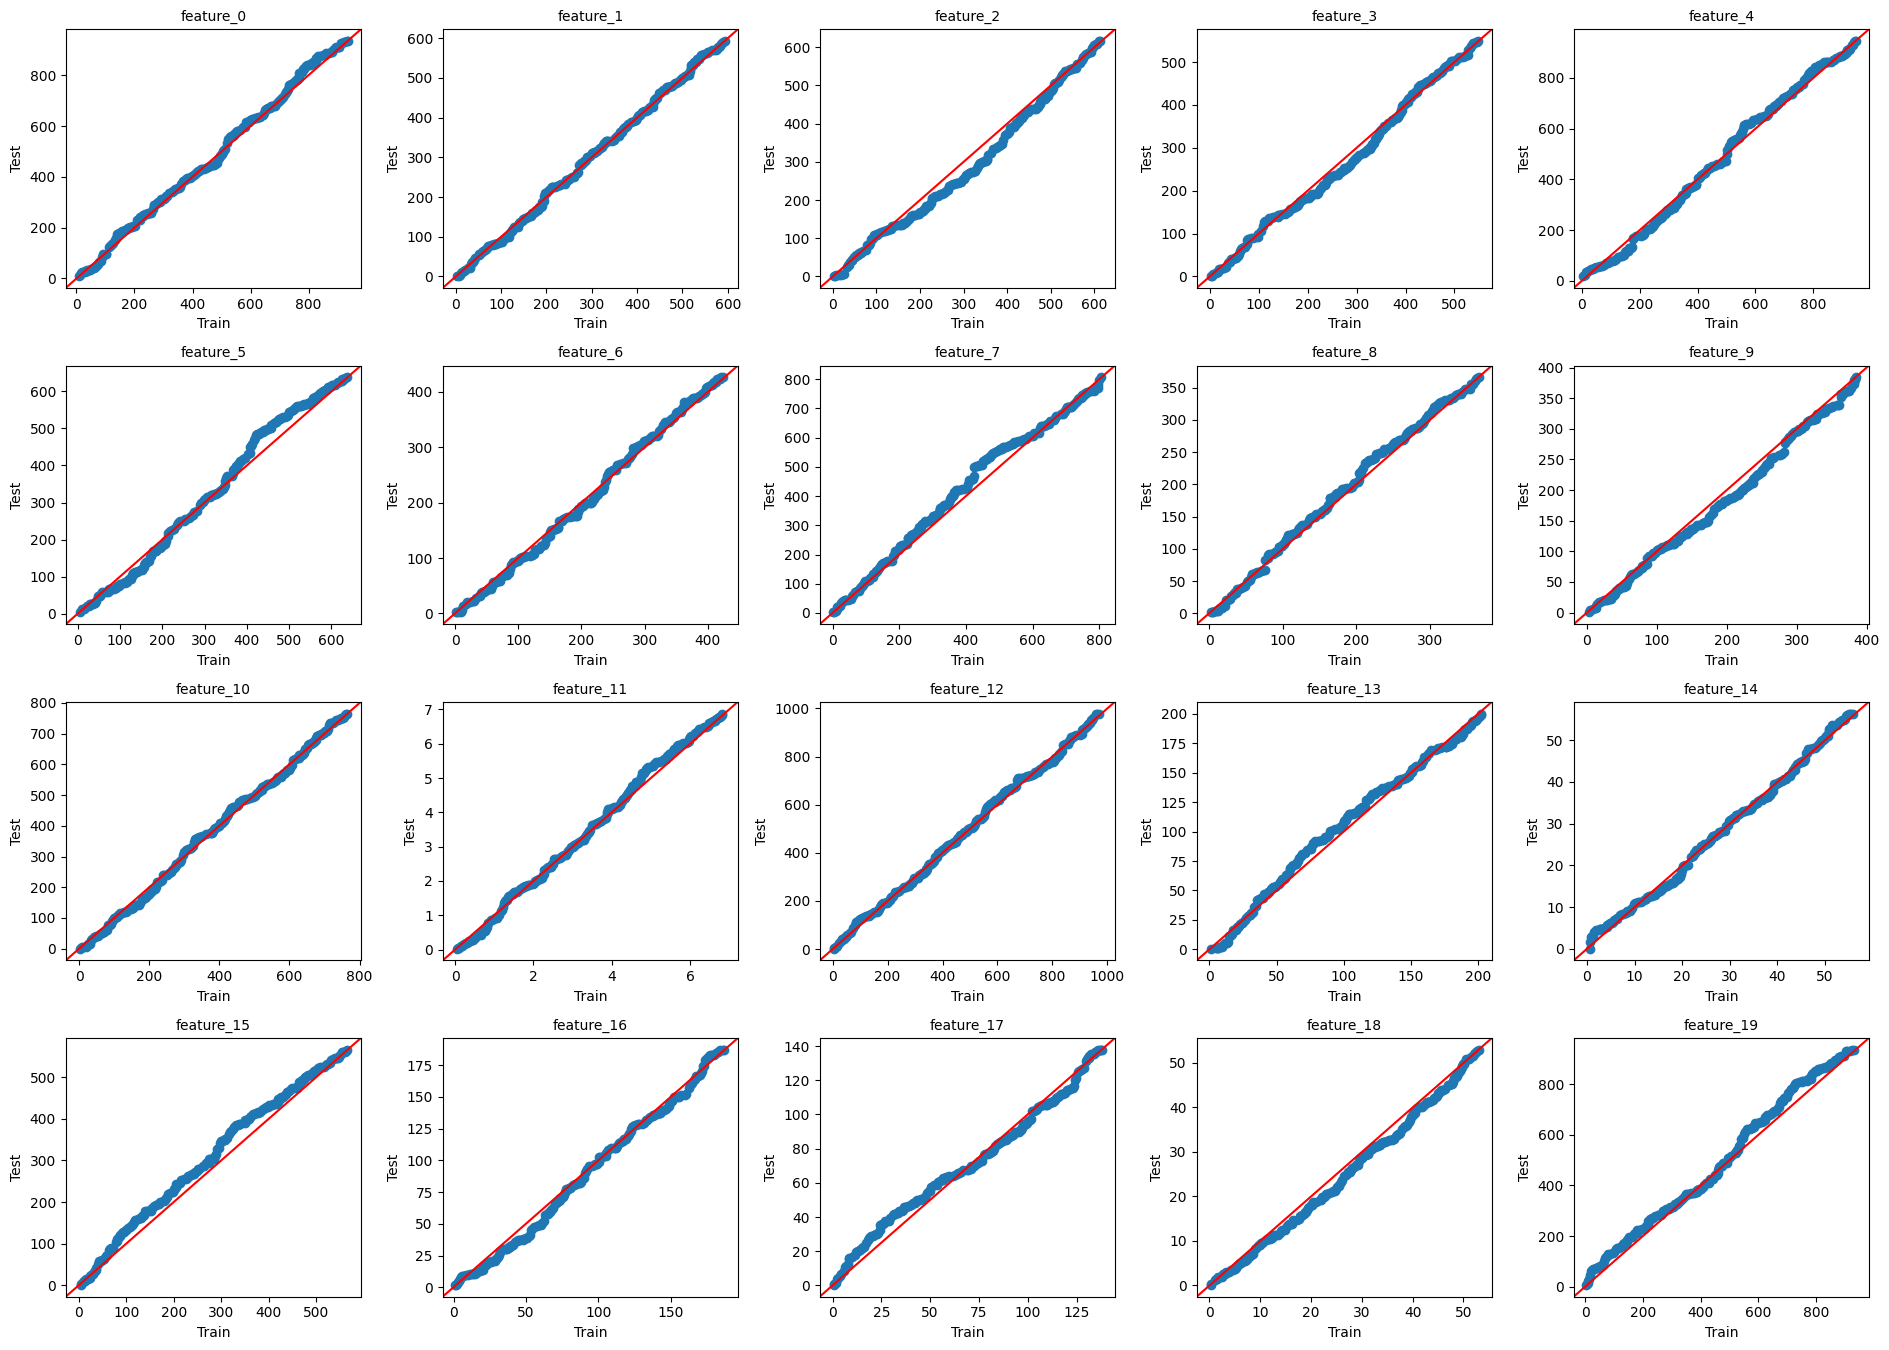

In [90]:
import statsmodels.api as sm
from statsmodels.graphics.gofplots import qqplot_2samples

num_cols = df_test.select_dtypes(include="number").columns
ncols = 5
nrows = int(np.ceil(len(num_cols) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(3.8 * ncols, 3.4 * nrows))
axes_flat = np.atleast_1d(axes).flat

for ax, col in zip(axes_flat, num_cols):
  pp_tr = sm.ProbPlot(df_train[col].dropna())
  pp_te = sm.ProbPlot(df_test[col].dropna())
  qqplot_2samples(pp_tr, pp_te, line="45", ax=ax)
  ax.set_title(col, fontsize=10)
  ax.set_xlabel("Train")
  ax.set_ylabel("Test")

for unused_ax in list(axes_flat)[len(num_cols) :]:
  unused_ax.set_visible(False)

plt.tight_layout()
plt.show()


### Correlations
Features 2,13,9, 11 show the highest correlations with the target variable, above 0.3.

In [36]:
df_train.corr()['target'].sort_values(ascending=False).to_frame('correlation_with_target')

,correlation_with_target
target,1.000000
feature_2,0.551767
feature_13,0.404697
feature_9,0.361942
feature_11,0.322802
feature_18,0.060052
feature_10,0.045485
feature_6,0.044443
feature_7,0.041089
feature_14,0.034944


### Visual Distribution

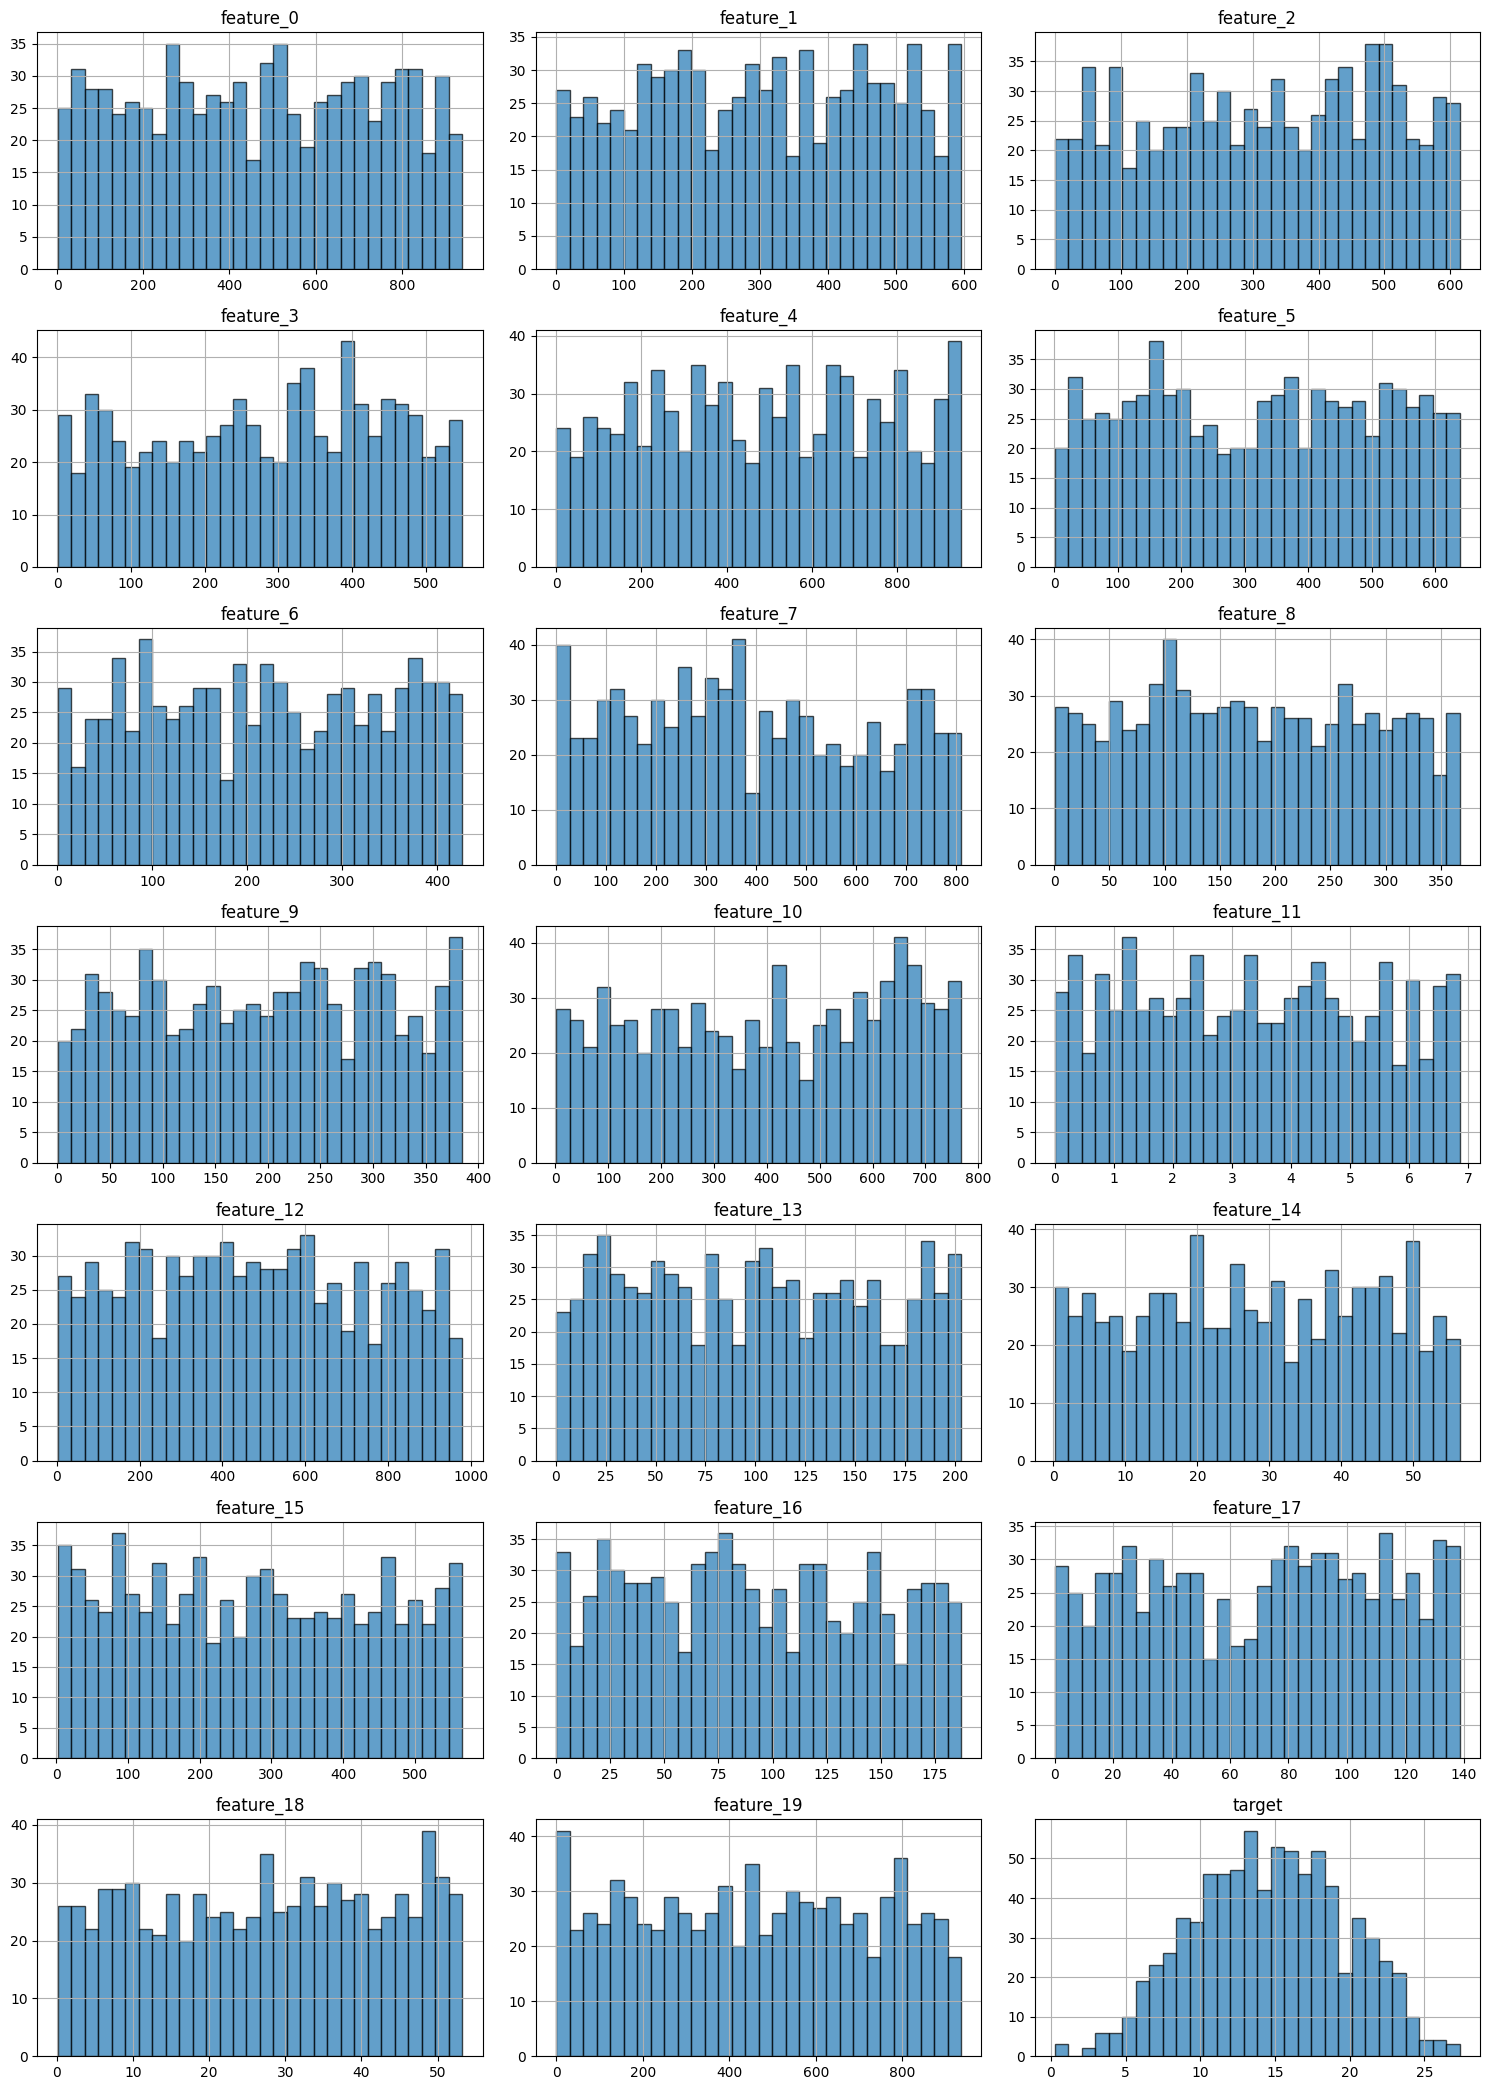

In [39]:
n_columns = 3
n_rows = (len(df_train.columns) + n_columns - 1) // n_columns

axes = df_train.hist(
    bins=30,
    figsize=(15, 21),
    layout=(n_rows, n_columns),
    edgecolor="black",
    alpha=0.7
)

plt.tight_layout()
plt.show()

### Multicollinearity
All variables in acceptable range, around of 1. VIF > 5 would indicate high multicollinearity. There's no need to drop nothing at this point.

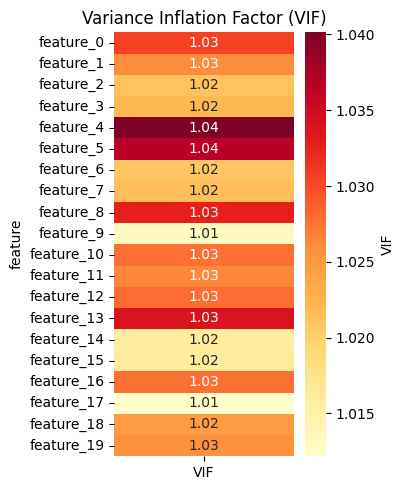

In [38]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
df_train_vars = df_train.drop(columns=['target'])

# Compute VIF for each feature
vif_df_train = pd.DataFrame({
    "feature": df_train_vars.columns,
    "VIF": [
        variance_inflation_factor(df_train_vars.values, i) for i in range(df_train_vars.shape[1])
    ],
}).set_index("feature")

# Plot VIF heatmap
plt.figure(figsize=(4, 5))
sns.heatmap(vif_df_train, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "VIF"})
plt.title("Variance Inflation Factor (VIF)")
plt.tight_layout()
plt.show()

## 2. Preprocessing
20% of the dataset was assigned for testing.

In [7]:
X, y = preprocess.get_feature_target(df_train, target_column=config.TARGET_COLUMN)
X_test = df_test
datautils.check_dim_datasets(X, X_test, (800, 200, 20))

X_train, X_val, y_train, y_val = preprocess.get_train_val_sets(X, y)
datautils.check_dim_datasets(X_train, X_val, (640, 160, 20))

Success: Train shape is correct!
Success: Test shape is correct!
Success: Train shape is correct!
Success: Test shape is correct!


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance

# 1. Non-linear & linear dependency check
mi = mutual_info_regression(X, y, random_state=42)

# 2. Interaction & predictive power check
rf = RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1).fit(X_train, y_train)
perm = permutation_importance(rf, X_val, y_val, n_repeats=10, random_state=42, n_jobs=-1)


diag = pd.DataFrame({
    "pearson_r": X.apply(lambda c: c.corr(y)).round(4),
    "mutual_info": mi.round(4),
    "perm_importance": perm.importances_mean.round(4),
}, index=X.columns).sort_values(by="perm_importance", ascending=False)

print(f"Validation R2: {rf.score(X_val, y_val):.4f}")
display(diag)


Validation R2: 0.7220


,pearson_r,mutual_info,perm_importance
feature_2,0.5518,0.1839,0.6028
feature_13,0.4047,0.1285,0.4208
feature_9,0.3619,0.0532,0.3691
feature_11,0.3228,0.0266,0.1434
feature_18,0.0601,0.0295,0.0684
feature_6,0.0444,0.0000,0.0029
feature_4,-0.0627,0.0123,0.0024
feature_0,0.0341,0.0000,0.0020
feature_8,0.0100,0.0000,0.0015
feature_7,0.0411,0.0000,0.0010


Depending on the shape of those variables that keep a non-linear relation with the target variable, we could chose an operation to flatten the data into a line. This could improve the model.

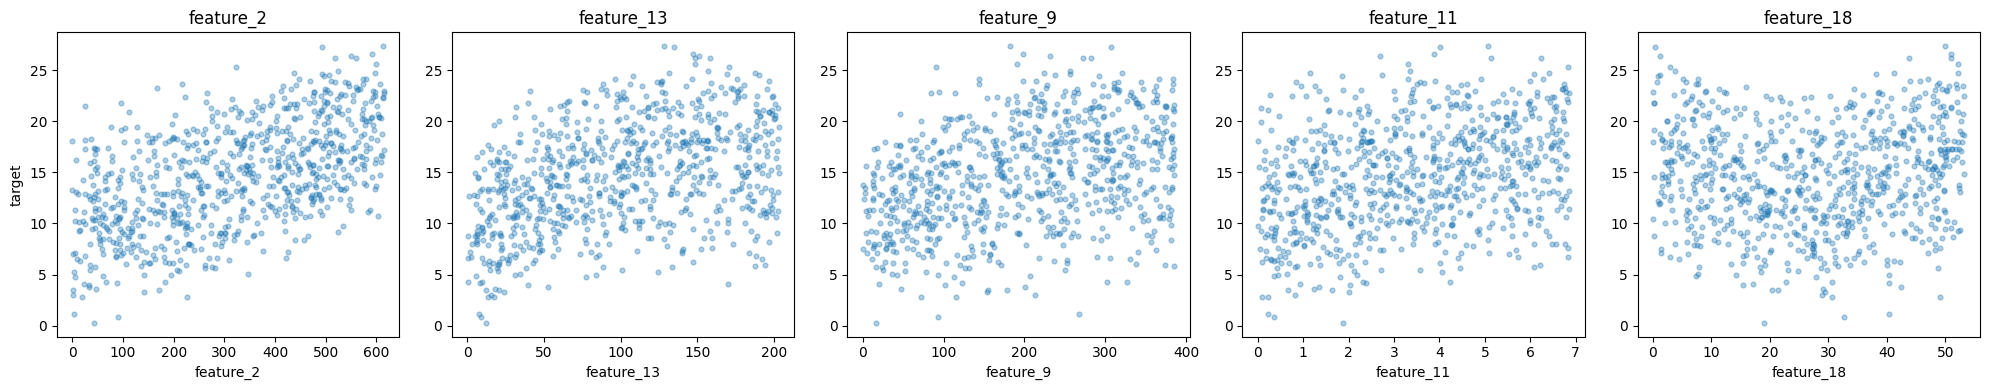

In [69]:
top_5 = ["feature_2", "feature_13", "feature_9", "feature_11", "feature_18"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, col in zip(axes, top_5):
    ax.scatter(df_train[col], df_train["target"], alpha=0.35, s=12)
    ax.set_title(col)
    ax.set_xlabel(col)
axes[0].set_ylabel("target")

plt.tight_layout()
plt.show()

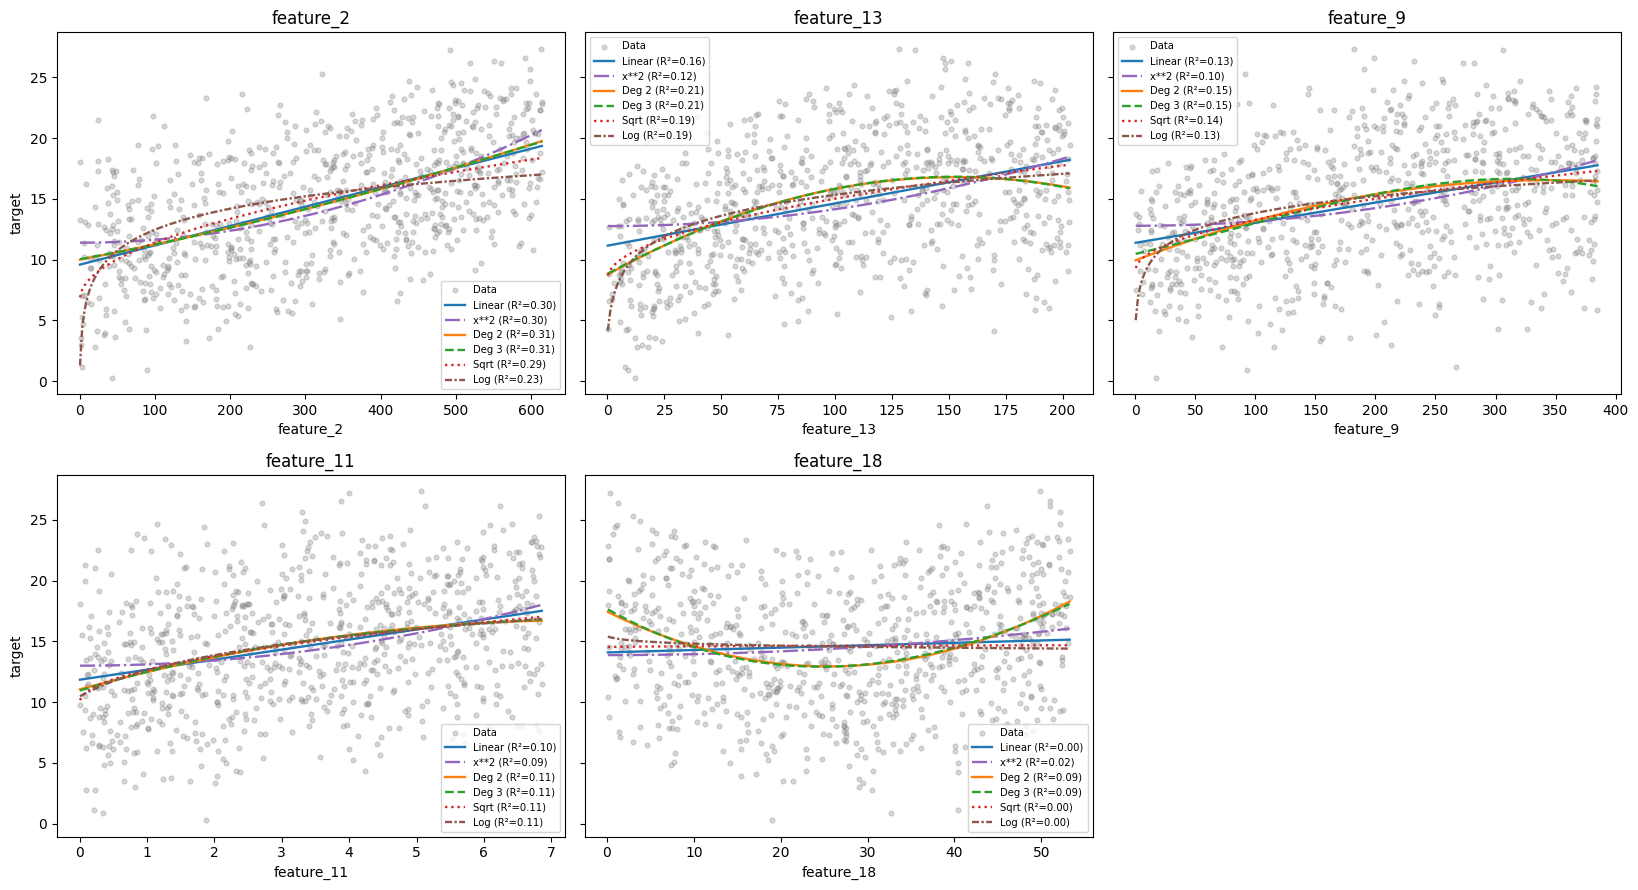

In [72]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures


def get_curve_models(shift):
  """Returns a dictionary of candidate models and their plot styles."""
  return {
      "Linear": (LinearRegression(), "tab:blue", "-"),
      "x**2": (
          make_pipeline(
              FunctionTransformer(lambda v: v**2), LinearRegression()
          ),
          "tab:purple",
          "-.",
      ),
      "Deg 2": (
          make_pipeline(PolynomialFeatures(2), LinearRegression()),
          "tab:orange",
          "-",
      ),
      "Deg 3": (
          make_pipeline(PolynomialFeatures(3), LinearRegression()),
          "tab:green",
          "--",
      ),
      "Sqrt": (
          make_pipeline(
              FunctionTransformer(lambda v, s=shift: np.sqrt(v + s)),
              LinearRegression(),
          ),
          "tab:red",
          ":",
      ),
      "Log": (
          make_pipeline(
              FunctionTransformer(lambda v, s=shift: np.log1p(v + s)),
              LinearRegression(),
          ),
          "tab:brown",
          (0, (3, 1, 1, 1)),
      ),
  }


def plot_feature_curves(df, features, target_col="target", ncols=3):
  """Plots scatter + fitted curve comparisons for a list of features."""
  nrows = int(np.ceil(len(features) / ncols))
  fig, axes = plt.subplots(
      nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows), sharey=True
  )
  axes_flat = np.atleast_1d(axes).flat

  for ax, col in zip(axes_flat, features):
    # Hide the unused 6th subplot (bottom-right)
    axes.flat[-1].set_visible(False) 
    valid = df[[col, target_col]].dropna()
    x = valid[[col]].values
    y = valid[target_col].values
    x_grid = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)
    shift = -x.min() if x.min() < 0 else 0.0

    ax.scatter(x, y, alpha=0.3, s=12, color="gray", label="Data")

    # Single loop replaces all 6 repetitive fit/plot blocks
    for label, (model, color, linestyle) in get_curve_models(shift).items():
      model.fit(x, y)
      r2 = model.score(x, y)
      ax.plot(
          x_grid,
          model.predict(x_grid),
          color=color,
          lw=1.7,
          linestyle=linestyle,
          label=f"{label} (R²={r2:.2f})",
      )

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.legend(fontsize=7.2, loc="best")

  # Hide any unused trailing subplots automatically
  for unused_ax in list(axes_flat)[len(features) :]:
    unused_ax.set_visible(False)

  # Label y-axis on the first column of every row
  for r in range(nrows):
    axes[r, 0].set_ylabel(target_col) if nrows > 1 else axes[0].set_ylabel(
        target_col
    )

  plt.tight_layout()
  plt.show()


top_5 = ["feature_2", "feature_13", "feature_9", "feature_11", "feature_18"]
plot_feature_curves(df_train, top_5)

* The assymetric down curve could end flattened with tradicional methods as log and square.
* The U-shape in feature 18 could be adressed with mean-centered squaring
* A version of the model using polynomial degree 2 and this 3 adicional variables was added to the experiments.
* However, Poly Deg 3 has shown the better performance.

## 3. Conclusions & Modeling Next Steps

1. **Data Integrity:** Both the training and test datasets match the expected dimensions and contain no missing (`null`) values.
2. **Distribution Consistency:** The feature distributions in the test dataset closely align with those in the training dataset, reducing the risk of covariate shift.
3. **Multicollinearity:** No features required removal due to severe multicollinearity.
4. **Feature Selection:** Model training will focus on the top 5 predictive features (`feature_2`, `feature_9`, `feature_11`, `feature_13`, and `feature_18`), which demonstrated the strongest relationships with the target variable.
5. **Feature Engineering:**
   * **`feature_13`:** Apply logarithmic ($\log$) and quadratic ($x^2$) transformations to capture non-linear scaling.
   * **`feature_18`:** Apply a mean-centered quadratic transformation ($(x - \bar{x})^2$) to capture symmetric curvature around its mean.
